In [384]:
pip install engineering_notation

In [385]:
import numpy as np
import matplotlib.pyplot as plt
from engineering_notation import EngNumber
from matplotlib.widgets import Slider, Button
from matplotlib.colors import Normalize
import matplotlib.cm as cm
import cmath
import matplotlib.colors as mcolors

# Dados do Transformador e do Filtro

In [386]:
V_fund = 34.5e3
f_fund = 60
w_fund = 2*np.pi*f_fund

S_trafo = 60e6
Z_baseTrafo = V_fund**2 / S_trafo
Z_trafo = ( 1.2e-3 + 1j*61e-3) * Z_baseTrafo

h_filtrar = 3
d = 0/100
h_0 = (1-d)*h_filtrar
Q_filtro = 2.8e6
FQual = np.array([20, 80])


In [387]:
X_F = V_fund**2 / Q_filtro

$${h_0}\,\omega  = \frac{1}{{\sqrt {L\,C} }} \Rightarrow h_0^2 = \frac{1}{{{\omega ^2}L\,C}} = \frac{1}{{\omega \,C\,\omega L}} = \frac{{{X_C}}}{{{X_L}}}$$

In [388]:
h02 = h_0**2

$$\left. \begin{gathered}
  {X_F} = {X_C} - {X_L} \hfill \\
  h_0^2 = \frac{{{X_C}}}{{{X_L}}} \hfill \\ 
\end{gathered}  \right\} \Rightarrow \left\{ \begin{gathered}
  {X_C} = \frac{1}{{h_0^2 - 1}}{X_F} \hfill \\
  {X_C} = \frac{{h_0^2}}{{h_0^2 - 1}}{X_F} \hfill \\ 
\end{gathered}  \right.$$

In [389]:
X_L =   1/(h02-1) * X_F
L = X_L / w_fund

In [390]:
X_C = h02/(h02-1) * X_F
C = 1 / ( X_C* w_fund )

In [391]:
f_max = ( 1 / np.sqrt(L*C) ) / ( 2 * np.pi )

### Fator de Qualidade $Q_0$ e Amorteciomento

O fator de qualidade, $Q_0$ determina o comportamento qualitativo de osciladores amortecidos simples e afeta outros circuitos, como a resposta dentro dos filtros.

Existem três regimes principais que podem ser considerados quando se refere ao amortecimento e ao fator $Q_0$.

* Subamortecimento $(Q_0 > 1/2)$

    Aqueles sistemas onde o fator $Q_0$ é apenas um pouco mais da metade podem oscilar uma ou duas vezes quando um impulso de degrau é aplicado antes que a oscilação desapareça. Conforme o fator de qualidade aumenta, o amortecimento diminui e as oscilações serão sustentadas por mais tempo. Em um sistema teórico onde o fator $Q_0$ é infinito, a oscilação é mantida indefinidamente sem a necessidade de adicionar qualquer fonte adicional. 

* Superamortecimento $(Q_0 < 1/2)$

    As perdas são altas e o sistema não tem overshoot. Em vez disso, o sistema irá decair exponencialmente, aproximando-se do valor do estado estacionário assintoticamente após a aplicação de um impulso ou degrau. À medida que o fator $Q_0$ é reduzido, o sistema responde mais lentamente à entrada.

* Amortecido criticamente $(Q = 1/2)$

    Para uma entrada degrau ou impulso a saída não oscila e não ultrapassa sua saída de estado estacionário. O sistema se aproximará da assíntota de estado estacionário no tempo mais rápido, sem qualquer ultrapassagem.


$$Q_0 = 2\pi \frac{{{W_{{\text{max_armazenada}}}}}}{{{W_{{\text{perdida}}}}}}=2\pi \frac{{\frac{{L{I^2}}}{2}}}{{R{I^2}\frac{{2\pi }}{f}}} = \frac{{\omega L}}{R} = \frac{1}{{\omega CR}} = \frac{{\sqrt {\frac{L}{C}} }}{R}$$
$$ $$
$${\text{Amortecimento}} = \frac{1}{{{Q_0}}} = \frac{R}{{\sqrt {\frac{L}{C}} }} = \frac{{{W_{{\text{perdida}}}}}}{{2\pi {W_{{\text{perdida}}}}}}$$

In [392]:
Z0 = np.sqrt(L/C)
R  = Z0 / FQual

In [393]:
Z_RL = R + 1j*X_L
Y_RL = 1 / Z_RL
R_paralelo = 1 / np.real(Y_RL)
X_L_paralelo = - 1 / np.imag(Y_RL)
L_paralelo = X_L_paralelo / w_fund

In [394]:
f = np.arange(60, 600.1, 0.1)
w = 2*np.pi*f
Zfiltro = np.zeros((len(FQual), len(f)), dtype=np.complex_)
Zmod    = np.zeros((len(FQual), len(f)))
Zang    = np.zeros((len(FQual), len(f)))
for k in range(len(FQual)):
    Zfiltro[k,:] = R[k] + 1j*w*L + 1/(1j*w*C)
    Zmod[k,:]    = np.abs(Zfiltro[k])
    Zang[k,:]    = np.angle(Zfiltro[k], deg=True)

## Filtro @ $60$ Hz

In [395]:
Ifiltro    = np.zeros((len(FQual)), dtype=np.complex_)
Vindutor   = np.zeros((len(FQual)), dtype=np.complex_)
Vcapacitor = np.zeros((len(FQual)), dtype=np.complex_)
Vresistor  = np.zeros((len(FQual)), dtype=np.complex_)
for k in range(len(FQual)):
    Ifiltro[k] = ( V_fund/np.sqrt(3) ) / Zfiltro[k,0]
    Vindutor[k]   =  1j * X_L * Ifiltro[k]
    Vcapacitor[k] = -1j * X_C * Ifiltro[k]
    Vresistor[k]  =      R[k] * Ifiltro [k]
    # conf = np.sqrt(3) * (Vresistor+Vcapacitor+Vindutor)
    # conf

In [396]:
I_Rparalelo  = np.zeros((len(FQual)), dtype=np.complex_)
I_Lparalelo  = np.zeros((len(FQual)), dtype=np.complex_)
I_Cserie     = np.zeros((len(FQual)), dtype=np.complex_)
V_Cserie     = np.zeros((len(FQual)), dtype=np.complex_)
for k in range(len(FQual)):
    I_Rparalelo[k] = ( Vindutor[k] + Vresistor[k] ) / R_paralelo[k]
    I_Lparalelo[k] = ( Vindutor[k] + Vresistor[k] ) / (1j*X_L_paralelo[k])
    I_Cserie[k]    = I_Rparalelo[k] + I_Lparalelo[k]
    V_Cserie[k]    = 1/(1j*w_fund*C)  * I_Cserie[k]
    # conf = np.sqrt(3) * (V_Cserie+I_Lparalelo*1j*X_L_paralelo)
    # conf

In [397]:
Qcap  = np.zeros((len(FQual)), dtype=np.complex_)
Qind  = np.zeros((len(FQual)), dtype=np.complex_)
Qfil  = np.zeros((len(FQual)))
Pfil  = np.zeros((len(FQual)))
for k in range(len(FQual)):
    Qcap[k] = 3 * Vcapacitor[k] * np.conj(Ifiltro[k])
    Qind[k] = 3 * Vindutor[k]   * np.conj(Ifiltro[k])
    Qfil[k] = np.imag( Qcap[k] - Qind[k] )
    Pfil[k] = 3 * R[k] * np.abs(Ifiltro[k])**2

## Transformador

In [398]:
X_trafo = np.imag(Z_trafo)/w_fund * w
R_trafo = np.real(Z_trafo) * w/w
Z_trafoFreq = R_trafo + 1j*X_trafo

## Filtro em paralelo com o transformador

In [399]:
Y_filtro = 1 / Zfiltro
Y_trafo  = 1 / Z_trafoFreq
Y_trafoFiltro = Y_filtro + Y_trafo
Z_trafoFiltro = 1 / Y_trafoFiltro

## Saídas

In [400]:
for k in range(len(FQual)):
    print('=============================')
    print('=== No circuito RLC série ===')
    print('=============================')
    print('   R    = ', EngNumber(R[k]))
    print('   L    = ', EngNumber(L))
    print('   C    = ', EngNumber(C))
    print('   Vcap = ', EngNumber(np.abs(Vcapacitor[k])), '\u2221', EngNumber(np.angle(Vcapacitor[k], deg=True)))
    print('   Vind = ', EngNumber(np.abs(Vindutor[k])),   '\u2221', EngNumber(np.angle(Vindutor[k],   deg=True)))
    print('   Iser = ', EngNumber(np.abs(Ifiltro[k])),    '\u2221', EngNumber(np.angle(Ifiltro[k],     deg=True)))
    print('   Sfil = ', EngNumber(Pfil[k]), '+ \u2149', EngNumber(Qfil[k]))
    print('=============================')

=== No circuito RLC série ===
   R    =  7.97
   L    =  140.95m
   C    =  5.55u
   Vcap =  22.40k ∡ -1.07
   Vind =  2.49k ∡ 178.93
   Iser =  46.85 ∡ 88.93
   Sfil =  52.48k + ⅉ -3.50M
=== No circuito RLC série ===
   R    =  1.99
   L    =  140.95m
   C    =  5.55u
   Vcap =  22.41k ∡ -268.57m
   Vind =  2.49k ∡ 179.73
   Iser =  46.86 ∡ 89.73
   Sfil =  13.12k + ⅉ -3.50M


In [401]:
for k in range(len(FQual)):
    print('===================================')
    print('      No circuito R//L+C           ')
    print('===================================')    
    print('   Rpar         = ', EngNumber(R_paralelo[k]))
    print('   Lpar         = ', EngNumber(L_paralelo[k]))
    print('   Cser         = ', EngNumber(C))
    print('   V_Cserie     = ', EngNumber(np.abs(V_Cserie[k])),    '\u2221', EngNumber(np.angle(V_Cserie[k],    deg=True)))
    print('   I_Cserie     = ', EngNumber(np.abs(I_Cserie[k])),    '\u2221', EngNumber(np.angle(I_Cserie[k],    deg=True)))
    print('   Vindparalelo = ', EngNumber(np.abs(Vindutor[k])),    '\u2221', EngNumber(np.angle(Vindutor[k],    deg=True)))
    print('   Iindparalelo = ', EngNumber(np.abs(I_Lparalelo[k])), '\u2221', EngNumber(np.angle(I_Lparalelo[k], deg=True)))
    print('   Iresparalelo = ', EngNumber(np.abs(I_Rparalelo[k])), '\u2221', EngNumber(np.angle(I_Rparalelo[k], deg=True)))
    print('===================================')

      No circuito R//L+C           
   Rpar         =  362.21
   Lpar         =  144.12m
   Cser         =  5.55u
   V_Cserie     =  22.40k ∡ -1.07
   I_Cserie     =  46.85 ∡ 88.93
   Vindparalelo =  2.49k ∡ 178.93
   Iindparalelo =  46.33 ∡ 80.40
   Iresparalelo =  6.95 ∡ 170.40
      No circuito R//L+C           
   Rpar         =  1.42k
   Lpar         =  141.15m
   Cser         =  5.55u
   V_Cserie     =  22.41k ∡ -268.57m
   I_Cserie     =  46.86 ∡ 89.73
   Vindparalelo =  2.49k ∡ 179.73
   Iindparalelo =  46.82 ∡ 87.58
   Iresparalelo =  1.76 ∡ 177.58


## Largura de faixa

In [402]:
w0 = 1 / np.sqrt(L*C)
Q0 = w0*L/R
BW = w0 / Q0
w1 = w0 - BW/2
w2 = w0 + BW/2

for k in range(len(FQual)):
    print('======================================================================')
    print('         R = ',EngNumber(R[k])      )
    print('======================================================================')    
    print('Largura de faixa             = ', EngNumber(BW[k]/(2*np.pi)), 'Hz')
    print('Fator de qualidade           = ', EngNumber(Q0[k]) )
    print('Frequência de ressonância    = ', EngNumber(w0/(2*np.pi)), 'Hz')
    print('Frequências de meia potência = ', EngNumber(w1[k]/(2*np.pi)), 'Hz e ', EngNumber(w2[k]/(2*np.pi)), 'Hz')
    print('======================================================================')

         R =  7.97
Largura de faixa             =  9 Hz
Fator de qualidade           =  20
Frequência de ressonância    =  180 Hz
Frequências de meia potência =  175.50 Hz e  184.50 Hz
         R =  1.99
Largura de faixa             =  2.25 Hz
Fator de qualidade           =  80
Frequência de ressonância    =  180 Hz
Frequências de meia potência =  178.87 Hz e  181.12 Hz


## Gráficos

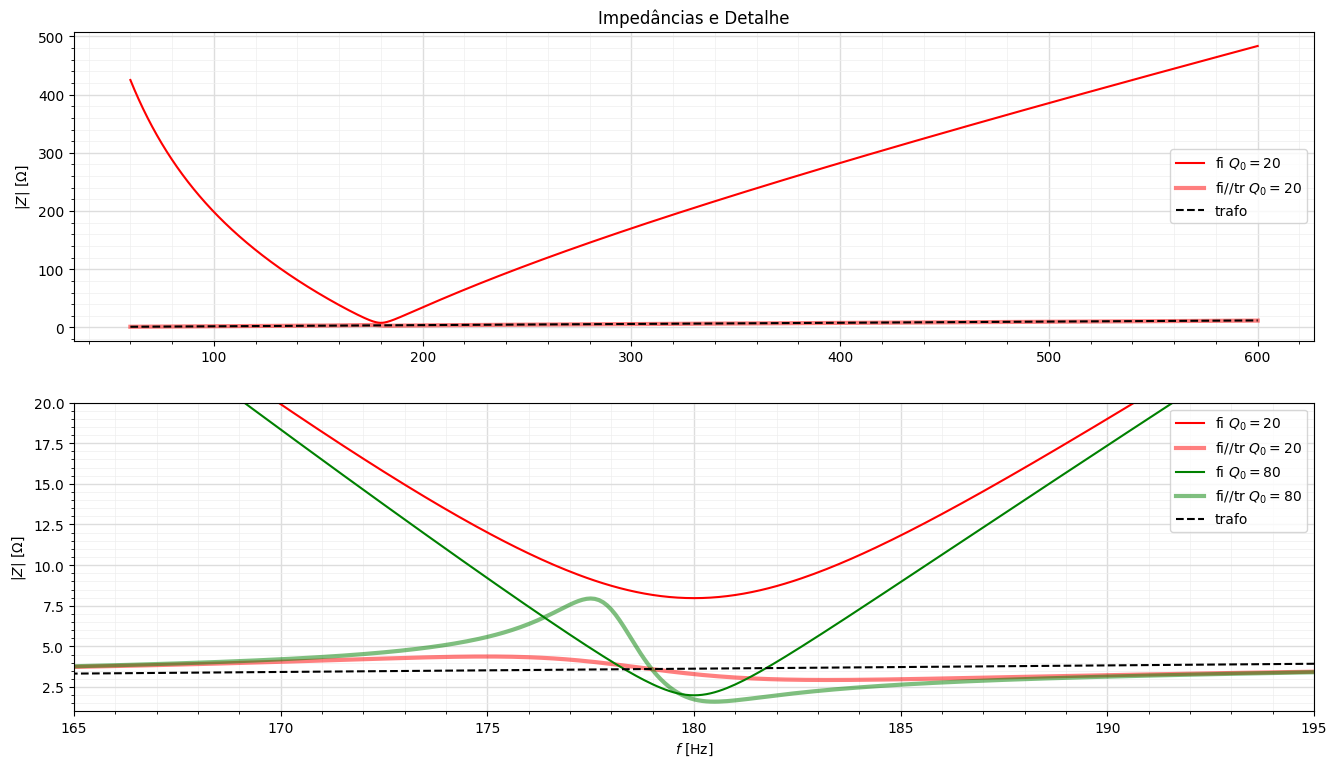

In [403]:
fig, axs = plt.subplots(2, 1)
fig.dpi = 100
fig.set_size_inches(16, 9)

k = 0
if k==0: cor='red'
if k==1: cor='green'
if k==2: cor='blue'

leg = 'fi $Q_0=$'+str(np.round(FQual[k],0))
axs[0].plot(f, Zmod[k], label=leg, color=cor)
leg = 'fi//tr $Q_0=$'+str(np.round(FQual[k],0))
axs[0].plot(f, np.abs(Z_trafoFiltro[k]), label=leg, lw=3, alpha=0.5, color=cor)

axs[0].plot(f, np.abs(Z_trafoFreq), label='trafo', ls='--', color='black')
axs[0].grid(which='major', color='#DDDDDD', linewidth=1.0)
axs[0].minorticks_on()
axs[0].grid(which='minor', color='#EEEEEE', linewidth=0.5)
axs[0].set_ylabel('$|Z|$ [$\Omega$]')
axs[0].set_title('Impedâncias e Detalhe')
axs[0].legend()


for k in range(len(FQual)):
    if k==0: cor='red'
    if k==1: cor='green'
    if k==2: cor='blue'
    leg = 'fi $Q_0=$'+str(np.round(FQual[k],0))
    axs[1].plot(f, Zmod[k], label=leg, color=cor)
    leg = 'fi//tr $Q_0=$'+str(np.round(FQual[k],0))
    axs[1].plot(f, np.abs(Z_trafoFiltro[k]), label=leg, lw=3, alpha=0.5, color=cor)
axs[1].grid(which='major', color='#DDDDDD', linewidth=1.0)
axs[1].minorticks_on()
axs[1].grid(which='minor', color='#EEEEEE', linewidth=0.5)
axs[1].set_ylim(1, 20)
axs[1].set_xlim(f_fund*(h_filtrar-1/4), f_fund*(h_filtrar+1/4))
axs[1].set_ylabel('$|Z|$ [$\Omega$]')
axs[1].plot(f, np.abs(Z_trafoFreq), label='trafo', ls='--', color='black')
axs[1].set_xlabel('$f$ [Hz]')
axs[1].legend()

plt.show()